# LTELayers Multi-Layer Plasma Modeling Tutorial

This tutorial demonstrates how to create and use the LTELayers model for multi-layer plasma simulations. The LTELayers model allows you to simulate plasmas with varying conditions along the optical path, which is more realistic for many LIBS applications.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import libskit

# Enable interactive plots
%matplotlib widget

## 1. Single Layer Equivalence

First, let's verify that a single-layer LTELayers model produces identical results to the standard LTEModel.

In [2]:
# Define common parameters (same as tutorial 2 multi-element plasma)
element_ratio = {"Ca": 0.4, "Si": 0.3, "Fe": 0.2, "Al": 0.1}
temperature = 10000.0      # Temperature in Kelvin
electron_density = 1e23    # Electron density in m^-3
length = 1e-3             # Plasma length in meters

# Create standard LTEModel
lte_model = libskit.LTEModel(element_ratio, temperature, electron_density, length)

# Create single-layer LTELayers (should be equivalent)
lte_layers_single = libskit.LTELayers(
    [element_ratio],        # Single element ratio
    [temperature],          # Single temperature
    [electron_density],     # Single electron density
    [length]               # Single length
)
lte_layers_double = libskit.LTELayers(
    [element_ratio, element_ratio],        # Single element ratio
    [temperature, temperature],          # Single temperature
    [electron_density, electron_density],     # Single electron density
    [length/2, length/2]               # Single length
)

## 2. Spectral Equivalence Test

Calculate spectra from both models to verify they produce identical results.

Maximum absolute difference: 0.00e+00
Maximum relative difference: 0.00e+00
Models are equivalent: True
Maximum absolute difference: 5.07e+11
Maximum relative difference: 1.26e-03
Models are equivalent: False


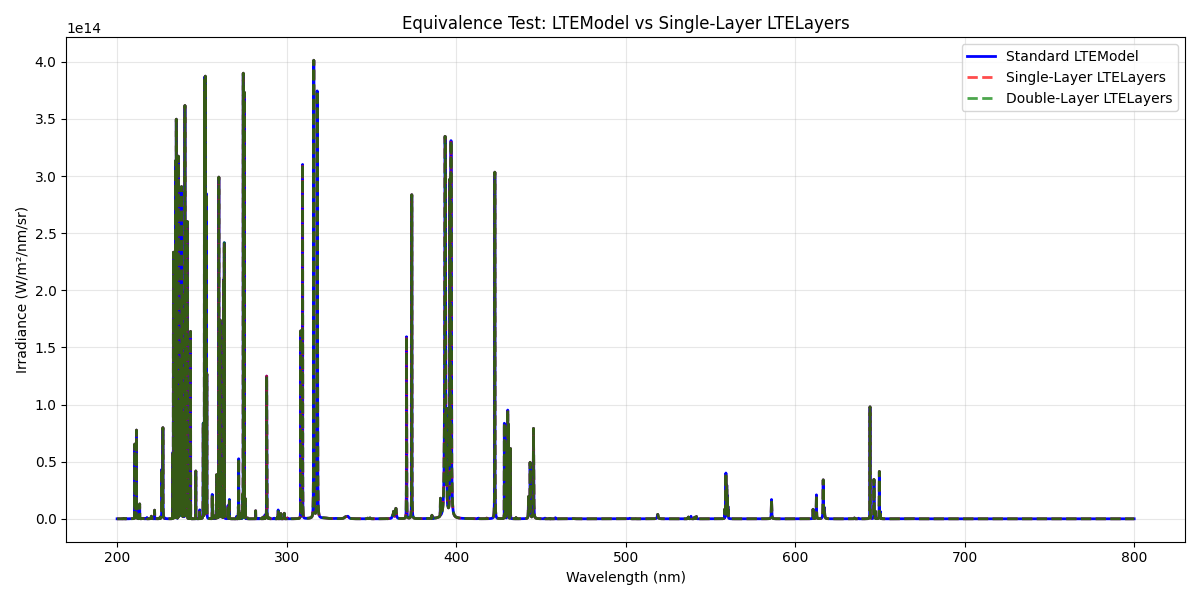

In [3]:
# Define wavelength range
wavelengths = np.arange(200, 800, 0.1)  # 400-500 nm range

# Calculate irradiance from both models
irradiance_lte = lte_model.calculate_irradiance(wavelengths)
irradiance_layers = lte_layers_single.calculate_irradiance(wavelengths)
irradiance_layers_2 = lte_layers_double.calculate_irradiance(wavelengths)

# Check equivalence
max_difference = np.max(np.abs(irradiance_lte - irradiance_layers))
max_value = np.max(irradiance_lte)
relative_difference = max_difference / max_value if max_value > 0 else 0

print(f"Maximum absolute difference: {max_difference:.2e}")
print(f"Maximum relative difference: {relative_difference:.2e}")
print(f"Models are equivalent: {relative_difference < 1e-10}")

# Check equivalence
max_difference = np.max(np.abs(irradiance_lte - irradiance_layers_2))
max_value = np.max(irradiance_lte)
relative_difference = max_difference / max_value if max_value > 0 else 0

print(f"Maximum absolute difference: {max_difference:.2e}")
print(f"Maximum relative difference: {relative_difference:.2e}")
print(f"Models are equivalent: {relative_difference < 1e-10}")

# Plot comparison
plt.figure(figsize=(12, 6))
plt.plot(wavelengths, irradiance_lte, 'b-', label='Standard LTEModel', linewidth=2)
plt.plot(wavelengths, irradiance_layers, 'r--', label='Single-Layer LTELayers', linewidth=2, alpha=0.7)
plt.plot(wavelengths, irradiance_layers_2, 'g--', label='Double-Layer LTELayers', linewidth=2, alpha=0.7)
plt.xlabel('Wavelength (nm)')
plt.ylabel('Irradiance (W/m²/nm/sr)')
plt.title('Equivalence Test: LTEModel vs Single-Layer LTELayers')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 3. Multi-Layer Plasma Model

Now let's create a realistic multi-layer plasma where the temperature decreases with distance from the sample surface, representing the cooling of the plasma plume.

In [4]:
# Create a two-layer plasma model
# Layer 0: Hot core (same as single layer)
# Layer 1: Cooler outer region (lower temperature, same composition)

element_ratios = [
    {"Ca": 0.4, "Si": 0.3, "Fe": 0.2, "Al": 0.1},  # Layer 0: Hot core
    {"Ca": 0.4, "Si": 0.3, "Fe": 0.2, "Al": 0.1}   # Layer 1: Cooler region (same composition)
]

temperatures = [
    10000.0,  # Layer 0: Hot core
    6000.0    # Layer 1: Cooler outer region
]

electron_densities = [
    1e23,     # Layer 0: High density core
    5e22      # Layer 1: Lower density outer region
]

lengths = [
    1e-3,     # Layer 0: Core region
    2e-3      # Layer 1: Extended outer region
]

# Create the multi-layer model
lte_layers_multi = libskit.LTELayers(element_ratios, temperatures, electron_densities, lengths)

print("Multi-Layer LTELayers Model:")
print(f"  Number of layers: {len(lte_layers_multi)}")
print("\n  Layer details:")
for i in range(len(lte_layers_multi)):
    layer = lte_layers_multi[i]
    print(f"    Layer {i}: T={layer.temperature:.0f}K, n_e={layer.electron_density:.1e}/m³, L={layer.length:.1e}m")

Multi-Layer LTELayers Model:
  Number of layers: 2

  Layer details:
    Layer 0: T=10000K, n_e=1.0e+23/m³, L=1.0e-03m
    Layer 1: T=6000K, n_e=5.0e+22/m³, L=2.0e-03m


## 4. Parameter Management

The LTELayers model uses a hierarchical parameter naming scheme to manage multiple layer parameters.

In [5]:
# Explore parameter management
param_names = lte_layers_multi.get_parameter_names()

print(f"Total parameters: {len(param_names)}")
print("\nParameter structure:")

# Group parameters by layer
layer_0_params = [name for name in param_names if name.startswith('layer_0_')]
layer_1_params = [name for name in param_names if name.startswith('layer_1_')]

print(f"  Layer 0 parameters ({len(layer_0_params)}): {layer_0_params[:5]}{'...' if len(layer_0_params) > 5 else ''}")
print(f"  Layer 1 parameters ({len(layer_1_params)}): {layer_1_params[:5]}{'...' if len(layer_1_params) > 5 else ''}")

# Demonstrate parameter access and modification
print(f"\nOriginal Layer 1 temperature: {lte_layers_multi.get_parameter('layer_1_temperature'):.0f}K")

# Modify Layer 1 temperature
lte_layers_multi.set_parameter('layer_1_temperature', 7000.0)
print(f"Modified Layer 1 temperature: {lte_layers_multi.get_parameter('layer_1_temperature'):.0f}K")

Total parameters: 14

Parameter structure:
  Layer 0 parameters (7): ['layer_0_temperature', 'layer_0_electron_density', 'layer_0_length', 'layer_0_Al', 'layer_0_Ca']...
  Layer 1 parameters (7): ['layer_1_temperature', 'layer_1_electron_density', 'layer_1_length', 'layer_1_Al', 'layer_1_Ca']...

Original Layer 1 temperature: 6000K
Modified Layer 1 temperature: 7000K


## 5. Spectral Comparison: Single vs Multi-Layer

Compare the spectral output from single-layer and multi-layer models to see the effect of plasma stratification.

Model comparison:
Single-layer: T=10000K, n_e=1.0e+23/m³, L=1.0e-03m
Multi-layer: Layer 0: T=10000K, Layer 1: T=6000K
Average model: T=8000K, n_e=7.5e+22/m³, L=3.0e-03m


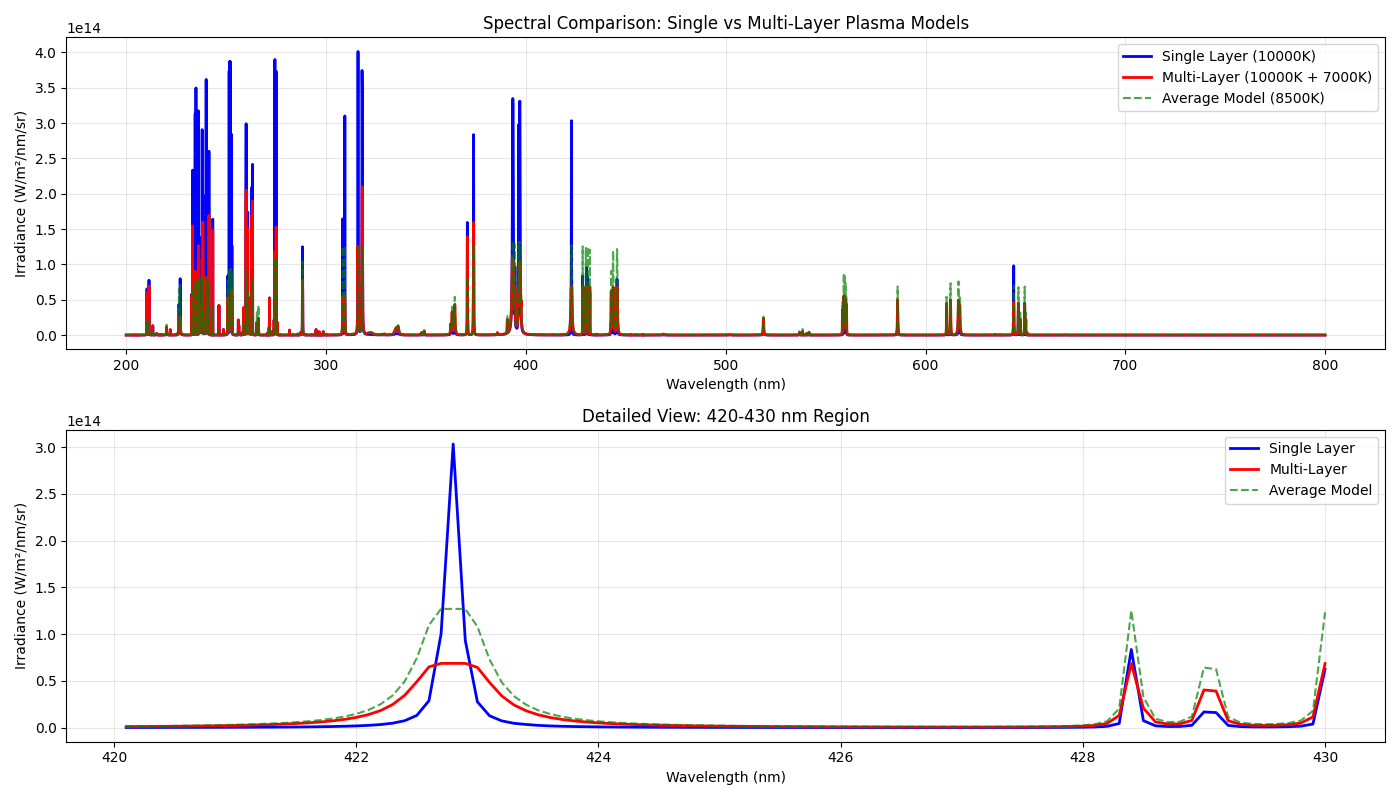

In [6]:
# Calculate irradiance from all three models
irradiance_single = lte_layers_single.calculate_irradiance(wavelengths)
irradiance_multi = lte_layers_multi.calculate_irradiance(wavelengths)

# Also create a simple average model for reference
avg_temp = np.mean(temperatures)
avg_density = np.mean(electron_densities)
avg_length = np.sum(lengths)  # Total path length
lte_avg = libskit.LTEModel(element_ratio, avg_temp, avg_density, avg_length)
irradiance_avg = lte_avg.calculate_irradiance(wavelengths)

print("Model comparison:")
print(f"Single-layer: T={temperature:.0f}K, n_e={electron_density:.1e}/m³, L={length:.1e}m")
print(f"Multi-layer: Layer 0: T={temperatures[0]:.0f}K, Layer 1: T={temperatures[1]:.0f}K")
print(f"Average model: T={avg_temp:.0f}K, n_e={avg_density:.1e}/m³, L={avg_length:.1e}m")

# Plot comparison
plt.figure(figsize=(14, 8))

# Full spectrum comparison
plt.subplot(2, 1, 1)
plt.plot(wavelengths, irradiance_single, 'b-', label='Single Layer (10000K)', linewidth=2)
plt.plot(wavelengths, irradiance_multi, 'r-', label='Multi-Layer (10000K + 7000K)', linewidth=2)
plt.plot(wavelengths, irradiance_avg, 'g--', label='Average Model (8500K)', linewidth=1.5, alpha=0.7)
plt.xlabel('Wavelength (nm)')
plt.ylabel('Irradiance (W/m²/nm/sr)')
plt.title('Spectral Comparison: Single vs Multi-Layer Plasma Models')
plt.legend()
plt.grid(True, alpha=0.3)

# Zoom in on interesting region
plt.subplot(2, 1, 2)
zoom_mask = (wavelengths >= 420) & (wavelengths <= 430)
plt.plot(wavelengths[zoom_mask], irradiance_single[zoom_mask], 'b-', label='Single Layer', linewidth=2)
plt.plot(wavelengths[zoom_mask], irradiance_multi[zoom_mask], 'r-', label='Multi-Layer', linewidth=2)
plt.plot(wavelengths[zoom_mask], irradiance_avg[zoom_mask], 'g--', label='Average Model', linewidth=1.5, alpha=0.7)
plt.xlabel('Wavelength (nm)')
plt.ylabel('Irradiance (W/m²/nm/sr)')
plt.title('Detailed View: 420-430 nm Region')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 7. Advanced Multi-Layer Configuration

Create a more complex multi-layer model with gradual temperature and density variations.

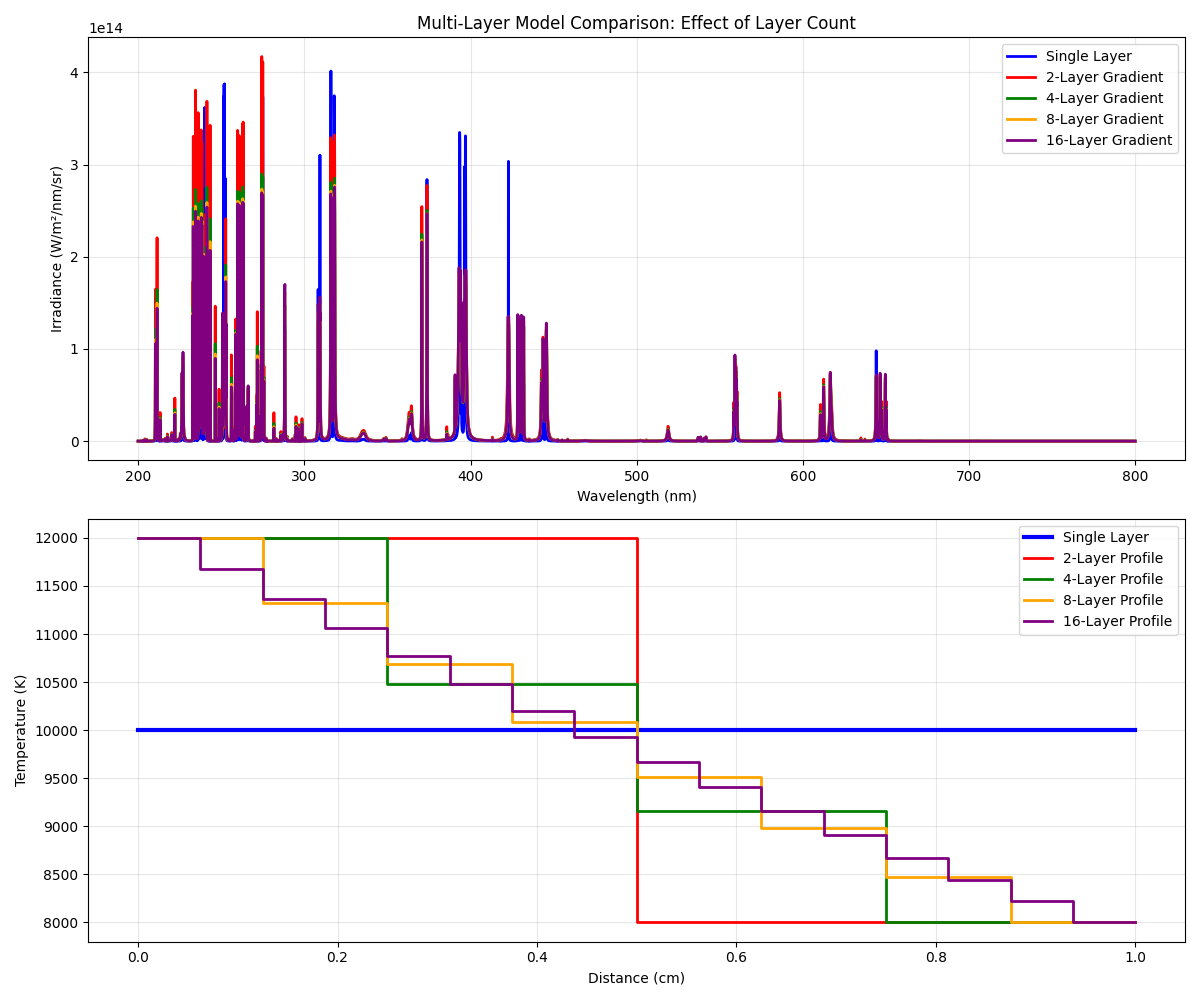

In [7]:
layers = [2, 4, 8, 16]

# Colors for different layer configurations
colors = ['red', 'green', 'orange', 'purple']

plt.figure(figsize=(12, 10))

# Top subplot: Spectral comparison
plt.subplot(2, 1, 1)
plt.plot(wavelengths, irradiance_single, 'b-', label='Single Layer', linewidth=2)

# Store temperature profiles for plotting
temperature_profiles = {}
all_irradiances = {}

for i, n_layers in enumerate(layers):
    base_elements = {"Ca": 0.4, "Si": 0.3, "Fe": 0.2, "Al": 0.1}

    # Temperature decreases exponentially from core to edge
    max_temp = 12000.0
    min_temp = 8000.0
    temps = [max_temp * np.exp(-j * np.log(max_temp/min_temp)/(n_layers-1)) for j in range(n_layers)]

    max_density = 2e23
    densities = [max_density for _ in temps]

    layer_length = 1e-3
    lengths = [layer_length/n_layers] * n_layers

    # Same composition for all layers
    element_ratios_grad = [base_elements] * n_layers

    # Create the gradient model
    lte_gradient = libskit.LTELayers(element_ratios_grad, temps, densities, lengths)

    # Calculate and plot
    irradiance_gradient = lte_gradient.calculate_irradiance(wavelengths)
    plt.plot(wavelengths, irradiance_gradient, color=colors[i], 
             label=f'{n_layers}-Layer Gradient', linewidth=2)
    
    # Store for analysis
    temperature_profiles[n_layers] = temps
    all_irradiances[n_layers] = irradiance_gradient

plt.xlabel('Wavelength (nm)')
plt.ylabel('Irradiance (W/m²/nm/sr)')
plt.title('Multi-Layer Model Comparison: Effect of Layer Count')
plt.legend()
plt.grid(True, alpha=0.3)


# Bottom subplot: Temperature profiles
plt.subplot(2, 1, 2)

# Single layer profile
plt.plot([0, length*1e3], [temperature, temperature], 'b-', linewidth=3, label='Single Layer')

# Multi-layer temperature profiles
layer_length = 1e-3
for i, n_layers in enumerate(layers):
    temps = temperature_profiles[n_layers]
    lengths_profile = [layer_length/n_layers] * n_layers
    
    # Create position array for step plot
    positions = np.cumsum([0] + lengths_profile[:-1])
    positions = np.append(positions, sum(lengths_profile)) * 1e3
    
    # Extend temperature profile for step plotting
    temps_extended = temps + [temps[-1]]
    
    plt.step(positions, temps_extended, color=colors[i], linewidth=2, 
             where='post', label=f'{n_layers}-Layer Profile')

plt.xlabel('Distance (cm)')
plt.ylabel('Temperature (K)')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()